# Análises complementares: diagnóstico, recorte regional e cobertura do SUS

Este notebook reúne três análises que complementam as perguntas 1, 2 e 3 do grupo:

- **Parte A:** a incidência menor no Norte/Nordeste é risco menor ou falta de diagnóstico?
- **Parte B:** recorte regional, comparando Alagoas, Nordeste e Sudeste/Sul em cobertura, tempo até o tratamento e mamógrafos.
- **Parte C:** exames de rastreamento do SUS por mulher (população feminina da base) comparados com a cobertura da PNS.

**Base utilizada:** `base_uf.csv` (base tratada, 27 UFs).

## Preparação dos dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, mannwhitneyu

df = pd.read_csv("../dados/tratados/base_uf.csv")
print("Linhas (UFs):", len(df))

# Conferências: como duas colunas da base foram construídas
razao_taxas = df["mort_taxa_ajustada_2023"] / df["incid_taxa_ajustada"]
print("razao_mortalidade_incidencia = mortalidade ajustada / incidência ajustada:",
      bool(np.allclose(df["razao_mortalidade_incidencia"], razao_taxas, atol=0.002)))
mamog = df["mamografos_em_uso_2024"] / df["pop_feminina_estimada"] * 1e5
print("mamografos_por_100mil_mulheres = mamógrafos em uso / mulheres (todas as idades):",
      bool(np.allclose(df["mamografos_por_100mil_mulheres"], mamog, atol=0.02)))

# Grupos usados nas comparações e cores por região
al = df[df["uf_sigla"] == "AL"].iloc[0]
ne = df[df["regiao"] == "Nordeste"]                  # 9 UFs (inclui Alagoas)
ss = df[df["grupo_comparacao"] == "Sul/Sudeste"]     # 7 UFs
cores = {"Norte": "#2a9d8f", "Nordeste": "#e9c46a", "Sudeste": "#e76f51",
         "Sul": "#264653", "Centro-Oeste": "#8d99ae"}

def fmt_p(p):
    return "< 0,001" if p < 0.001 else f"{p:.3f}".replace(".", ",")

Linhas (UFs): 27
razao_mortalidade_incidencia = mortalidade ajustada / incidência ajustada: True
mamografos_por_100mil_mulheres = mamógrafos em uso / mulheres (todas as idades): True


**Duas observações sobre a base:**

- `razao_mortalidade_incidencia` é a razão entre as **taxas ajustadas** (mortalidade ÷ incidência). O notebook da Pergunta 1 usa **óbitos ÷ casos**, que é outra medida, por isso os valores diferem (ex.: Alagoas 0,33 aqui e 0,36 lá). A razão entre taxas ajustadas é a mais adequada para comparar UFs, porque remove o efeito da idade. Vale o grupo usar uma só e deixar isso explícito no relatório.
- `mamografos_por_100mil_mulheres` usa como denominador as mulheres de **todas as idades**, e não só as de 50 a 69 anos.

## Parte A: a incidência menor no Norte/Nordeste é risco menor ou falta de diagnóstico?

**Ideia:** um estado que rastreia pouco também diagnostica pouco. Parte da incidência menor no Norte/Nordeste pode ser caso que não chega a ser registrado, e não um risco realmente menor. Esta parte testa se os dados são **compatíveis** com essa hipótese. Ela não consegue prová-la.

**Indicadores:**
- Incidência: taxa ajustada por idade (`incid_taxa_ajustada`), estimativa INCA 2023–2025
- Mortalidade: taxa ajustada por idade, 2023
- Cobertura de mamografia: PNS 2019 (`cobertura_pns_2019`)
- Oferta: mamógrafos em uso por 100 mil mulheres, CNES 2024

### A.1 Incidência × cobertura e incidência × oferta de mamógrafos

Se UFs que rastreiam mais também têm incidência maior, isso é compatível com a hipótese. Usamos a **correlação de Spearman**, que funciona com 27 UFs e não exige distribuição normal.

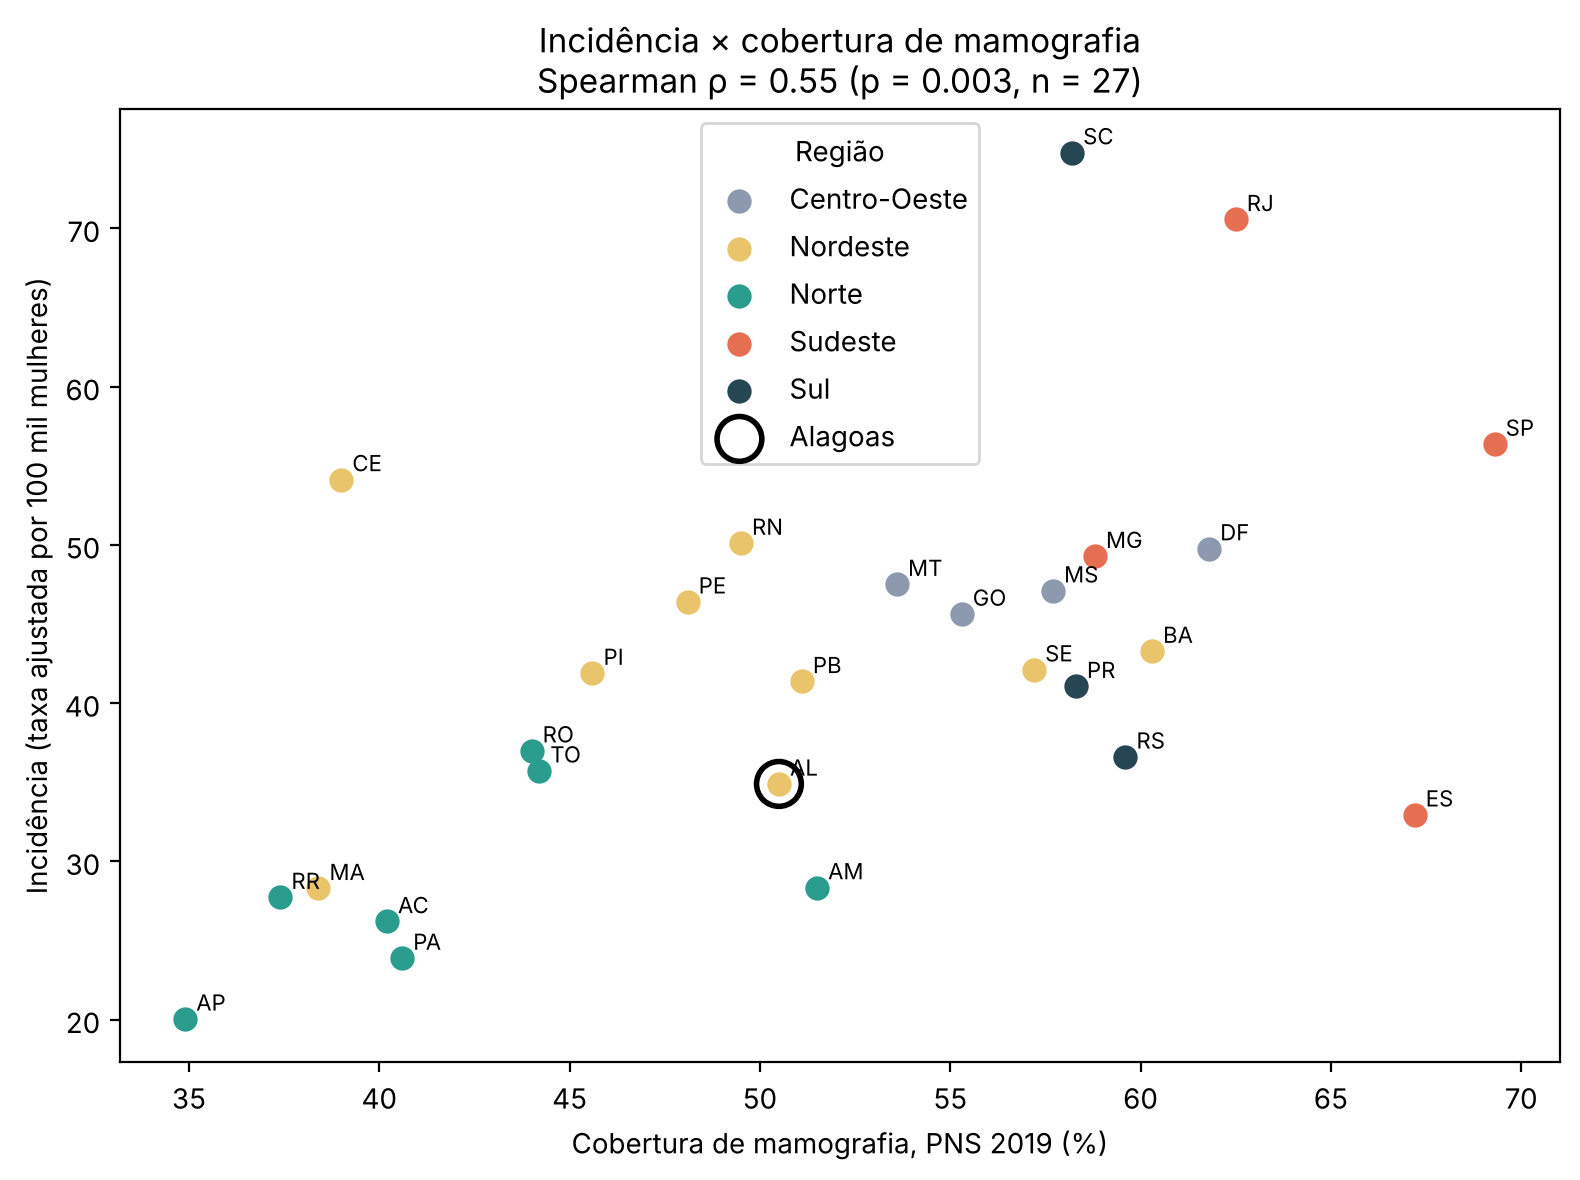

In [2]:
def dispersao(x, xlabel, titulo):
    fig, ax = plt.subplots(figsize=(8, 6))
    for regiao, g in df.groupby("regiao"):
        ax.scatter(g[x], g["incid_taxa_ajustada"], color=cores[regiao], label=regiao, s=60)
    a = df[df["uf_sigla"] == "AL"]
    ax.scatter(a[x], a["incid_taxa_ajustada"], s=260, facecolors="none",
               edgecolors="black", linewidths=2, label="Alagoas")
    for _, r in df.iterrows():
        ax.annotate(r["uf_sigla"], (r[x], r["incid_taxa_ajustada"]),
                    xytext=(4, 3), textcoords="offset points", fontsize=8)
    rho, p = spearmanr(df[x], df["incid_taxa_ajustada"])
    ax.set_title(f"{titulo}\nSpearman ρ = {rho:.2f} (p = {p:.3f}, n = {len(df)})")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Incidência (taxa ajustada por 100 mil mulheres)")
    ax.legend(title="Região")
    plt.tight_layout()
    plt.show()

dispersao("cobertura_pns_2019", "Cobertura de mamografia, PNS 2019 (%)",
          "Incidência × cobertura de mamografia")

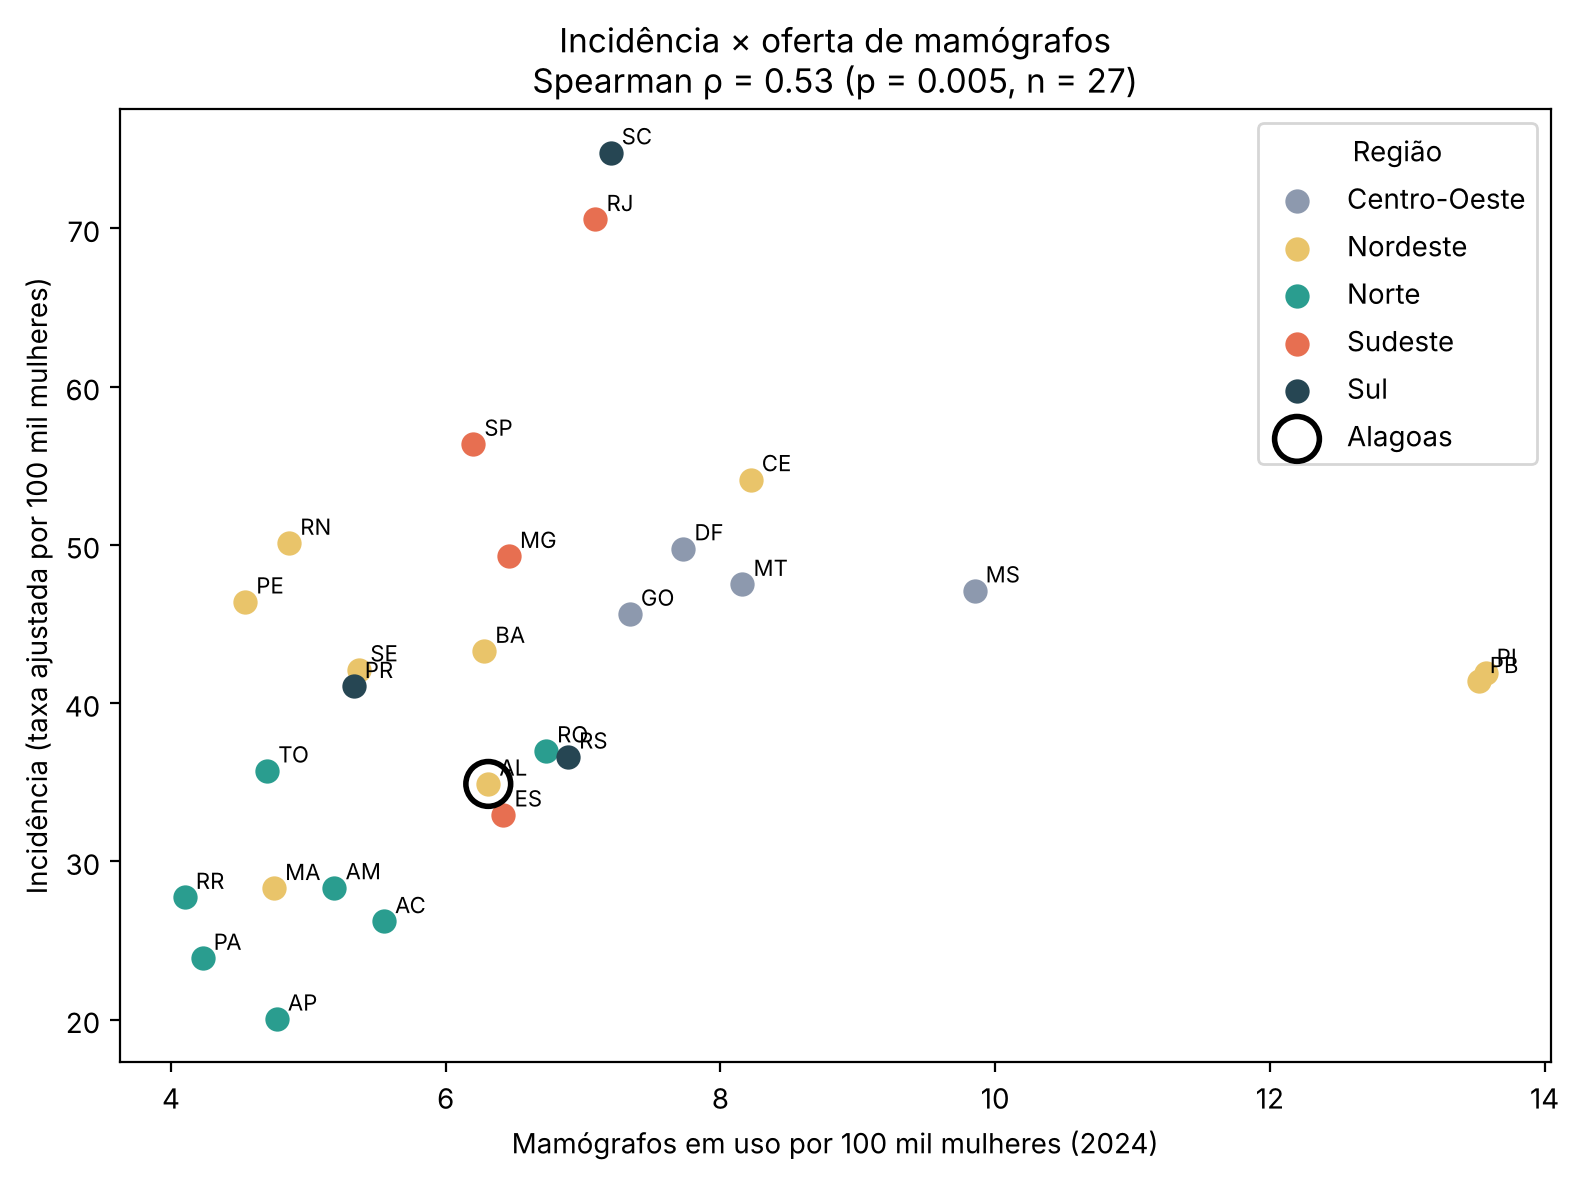

In [3]:
dispersao("mamografos_por_100mil_mulheres", "Mamógrafos em uso por 100 mil mulheres (2024)",
          "Incidência × oferta de mamógrafos")

### A.2 Correlações de Spearman

Além do conjunto das 27 UFs, olhamos separadamente o grupo **Norte/Nordeste** (16 UFs) e o grupo **Sul/Sudeste** (7 UFs). O Centro-Oeste (4 UFs) fica de fora por ter poucas UFs.

In [4]:
rotulos = {
    "incid_taxa_ajustada": "Incidência ajustada",
    "mort_taxa_ajustada_2023": "Mortalidade ajustada 2023",
    "razao_mortalidade_incidencia": "Razão mortalidade/incidência",
    "cobertura_pns_2019": "Cobertura PNS 2019",
    "mamografos_por_100mil_mulheres": "Mamógrafos por 100 mil mulheres",
}

pares = [
    ("incid_taxa_ajustada", "cobertura_pns_2019"),
    ("incid_taxa_ajustada", "mamografos_por_100mil_mulheres"),
    ("mort_taxa_ajustada_2023", "cobertura_pns_2019"),
    ("mort_taxa_ajustada_2023", "mamografos_por_100mil_mulheres"),
    ("razao_mortalidade_incidencia", "cobertura_pns_2019"),
    ("razao_mortalidade_incidencia", "mamografos_por_100mil_mulheres"),
    ("incid_taxa_ajustada", "razao_mortalidade_incidencia"),
    ("cobertura_pns_2019", "mamografos_por_100mil_mulheres"),
]

def tabela_spearman(dados, nome):
    linhas = []
    for a, b in pares:
        rho, p = spearmanr(dados[a], dados[b])
        linhas.append({"Grupo": nome, "Variável 1": rotulos[a], "Variável 2": rotulos[b],
                       "ρ": round(rho, 2), "p": fmt_p(p), "n": len(dados)})
    return pd.DataFrame(linhas)

tabela_spearman(df, "Todas as UFs")

,Grupo,Variável 1,Variável 2,ρ,p,n
0,Todas as UFs,Incidência ajustada,Cobertura PNS 2019,0.55,"0,003",27
1,Todas as UFs,Incidência ajustada,Mamógrafos por 100 mil mulheres,0.53,"0,005",27
2,Todas as UFs,Mortalidade ajustada 2023,Cobertura PNS 2019,0.44,"0,021",27
3,Todas as UFs,Mortalidade ajustada 2023,Mamógrafos por 100 mil mulheres,0.12,"0,556",27
4,Todas as UFs,Razão mortalidade/incidência,Cobertura PNS 2019,-0.17,"0,397",27
5,Todas as UFs,Razão mortalidade/incidência,Mamógrafos por 100 mil mulheres,-0.42,"0,029",27
6,Todas as UFs,Incidência ajustada,Razão mortalidade/incidência,-0.69,"< 0,001",27
7,Todas as UFs,Cobertura PNS 2019,Mamógrafos por 100 mil mulheres,0.38,"0,051",27


In [5]:
grupos = pd.concat([
    tabela_spearman(df[df["grupo_comparacao"] == "Norte/Nordeste"], "Norte/Nordeste"),
    tabela_spearman(df[df["grupo_comparacao"] == "Sul/Sudeste"], "Sul/Sudeste"),
])
grupos[(grupos["Variável 1"] == "Incidência ajustada") &
       (grupos["Variável 2"].isin(["Cobertura PNS 2019", "Mamógrafos por 100 mil mulheres"]))]

,Grupo,Variável 1,Variável 2,ρ,p,n
0,Norte/Nordeste,Incidência ajustada,Cobertura PNS 2019,0.52,"0,040",16
1,Norte/Nordeste,Incidência ajustada,Mamógrafos por 100 mil mulheres,0.42,"0,107",16
0,Sul/Sudeste,Incidência ajustada,Cobertura PNS 2019,-0.29,"0,535",7
1,Sul/Sudeste,Incidência ajustada,Mamógrafos por 100 mil mulheres,0.54,"0,215",7


**Como ler a tabela:** ρ varia de −1 a +1, e quanto mais perto de zero, mais fraca a relação. Os p-valores são **descritivos**: foram feitos vários testes sem correção para múltiplas comparações, então um resultado isolado com p próximo de 0,05 deve ser lido com cautela. Com 7 UFs (Sul/Sudeste), o teste tem pouquíssimo poder, e a ausência de significância não indica ausência de relação.

**Atenção à razão:** a correlação entre a razão mortalidade/incidência e a incidência (ρ ≈ −0,69) aparece em grande parte **por construção**, porque a incidência está no denominador da razão. Ela não deve ser usada como evidência.

### A.3 Alagoas em relação ao Nordeste

As médias e medianas do Nordeste são calculadas **a partir das 9 UFs**, e não da linha regional da planilha de incidência.

In [6]:
cols = ["incid_taxa_ajustada", "mort_taxa_ajustada_2023", "razao_mortalidade_incidencia",
        "cobertura_pns_2019", "mamografos_por_100mil_mulheres"]
posicao = df[cols].rank(ascending=False)[df["uf_sigla"] == "AL"].iloc[0]

tab_al = pd.DataFrame({
    "Alagoas": al[cols].astype(float),
    "Média do Nordeste (9 UFs)": ne[cols].mean(),
    "Mediana do Nordeste": ne[cols].median(),
    "Posição de AL entre 27 (1 = maior)": posicao.astype(int),
}).round(2)
tab_al.index = [rotulos[c] for c in cols]
tab_al

,Alagoas,Média do Nordeste (9 UFs),Mediana do Nordeste,Posição de AL entre 27 (1 = maior)
Incidência ajustada,34.89,42.50,42.11,20
Mortalidade ajustada 2023,11.59,11.07,11.59,16
Razão mortalidade/incidência,0.33,0.26,0.26,7
Cobertura PNS 2019,50.50,48.86,49.50,16
Mamógrafos por 100 mil mulheres,6.31,7.49,6.28,14


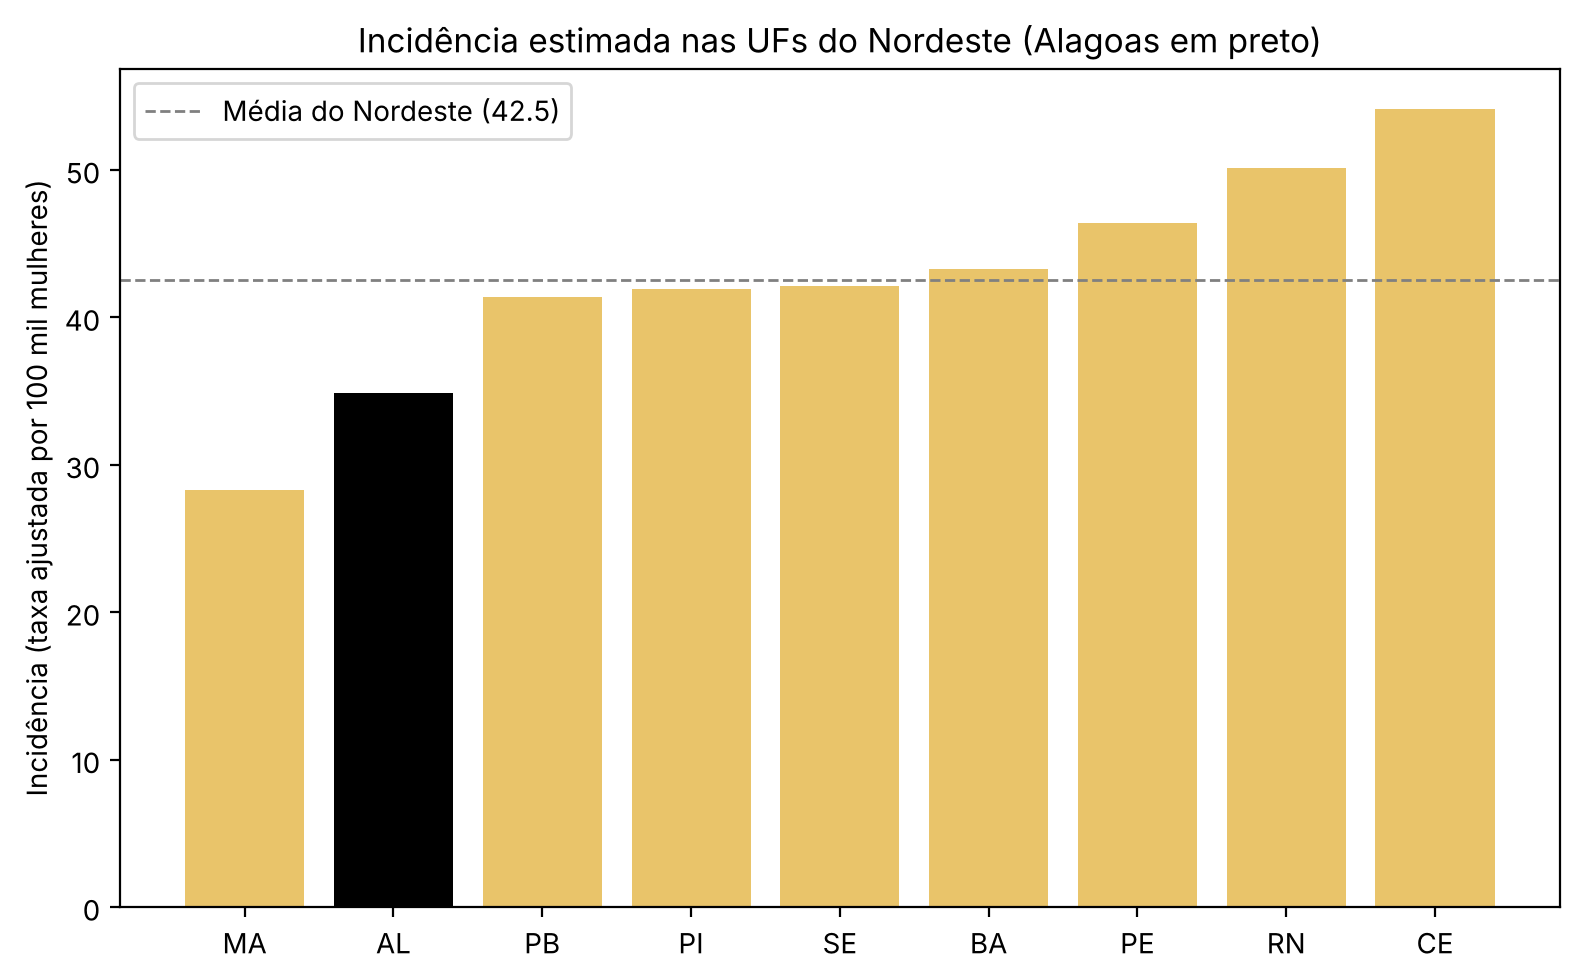

In [7]:
ne_ord = ne.sort_values("incid_taxa_ajustada")
fig, ax = plt.subplots(figsize=(8, 5))
cor_barra = ["black" if u == "AL" else cores["Nordeste"] for u in ne_ord["uf_sigla"]]
ax.bar(ne_ord["uf_sigla"], ne_ord["incid_taxa_ajustada"], color=cor_barra)
ax.axhline(ne["incid_taxa_ajustada"].mean(), color="gray", linestyle="--", linewidth=1,
           label=f"Média do Nordeste ({ne['incid_taxa_ajustada'].mean():.1f})")
ax.set_ylabel("Incidência (taxa ajustada por 100 mil mulheres)")
ax.set_title("Incidência estimada nas UFs do Nordeste (Alagoas em preto)")
ax.legend()
plt.tight_layout()
plt.show()

### A.4 Interpretação

**O que os dados mostram.** UFs com cobertura de mamografia mais alta e mais mamógrafos por mulher tendem a ter incidência estimada mais alta (ρ ≈ 0,55 e 0,53, ambos com p < 0,01). Isso é **compatível** com a hipótese de que parte da incidência menor no Norte/Nordeste é diagnóstico que não acontece. Mas não a prova: UFs com mais cobertura também costumam ter mais renda, mais urbanização e outro perfil de risco, e esses fatores não foram controlados. Dentro do grupo Norte/Nordeste a relação com a cobertura se mantém (ρ ≈ 0,52, p ≈ 0,04). No Sul/Sudeste, com só 7 UFs, não dá para concluir nada.

**Mortalidade.** A mortalidade ajustada também é maior nas UFs com mais cobertura (ρ ≈ 0,44), mas não nas com mais mamógrafos (ρ ≈ 0,12, p ≈ 0,56). A primeira relação é pouco intuitiva se o rastreamento reduzisse mortes, e provavelmente reflete diferenças de risco e de estrutura da população entre as UFs, e não o efeito do rastreamento, que esses dados não permitem medir.

**Razão mortalidade/incidência.** A razão cai quando há mais mamógrafos por mulher (ρ ≈ −0,42, p ≈ 0,03), mas não com a cobertura da PNS (ρ ≈ −0,17, p ≈ 0,40). Esse padrão é o esperado se UFs com mais oferta detectam mais casos sem que a mortalidade suba na mesma proporção, mas também pode vir só do fato de a incidência estar no denominador. Além disso, a incidência do INCA é estimada, em parte, pela razão entre incidência e mortalidade usando os óbitos do SIM, então a razão carrega certa circularidade.

**Alagoas.** A incidência ajustada é de 34,9, a 20ª posição entre as 27 UFs, contra 42,5 na média do Nordeste. A cobertura PNS (50,5%) fica acima da média do Nordeste (48,9%), e a oferta de mamógrafos (6,3 por 100 mil mulheres) está praticamente na mediana do Nordeste (6,3), já que a média (7,5) é puxada por Paraíba e Piauí. A mortalidade (11,6) fica um pouco acima da média regional (11,1), e a razão (0,33) é a 7ª maior do país, contra 0,26 na média do Nordeste. Ou seja, Alagoas tem cobertura e oferta típicas do Nordeste, mas incidência estimada menor e mortalidade não menor. A falta de rastreamento, sozinha, não explica Alagoas. Ficam em aberto diagnóstico mais tardio, sub-registro ou imprecisão da estimativa, e esses dados não distinguem entre eles.

**Conclusão da Parte A.** Os dados são compatíveis com a hipótese de subdiagnóstico em parte do Norte/Nordeste, mas não permitem separar "risco menor" de "menos diagnóstico".

### A.5 Limitações

- **Dados agregados por UF (falácia ecológica) e n = 27.** As correlações descrevem UFs, não mulheres. Os testes são exploratórios e não foram corrigidos para múltiplas comparações.
- **Períodos diferentes.** Cobertura PNS de 2019, mamógrafos de 2024, incidência estimada de 2023–2025 e mortalidade de 2023.
- **Incidência é estimativa.** O INCA usa modelos de tendência ou a razão incidência/mortalidade, com óbitos do SIM. A razão mortalidade/incidência é, por isso, parcialmente circular, e sua correlação com a incidência é em parte mecânica.
- **Mamógrafos.** O indicador usa mamógrafos em uso ÷ mulheres de todas as idades. O total nacional da base (cerca de 7,2 mil) é compatível com contagem de público e privado, e não só do SUS. Confirmar no dicionário de dados. Paraíba e Piauí aparecem com cerca de 13,5 mamógrafos por 100 mil mulheres, o dobro da maioria das UFs: conferir se é dado real ou contagem dupla (o CNES pode contar o mesmo aparelho em mais de uma categoria). O Spearman é pouco sensível a esses dois pontos, mas eles puxam a média do Nordeste (7,5, contra mediana de 6,3).
- **PNS.** É pesquisa por amostra, autorreferida, e a cobertura inclui qualquer serviço (SUS, plano e particular). A base não traz intervalo de confiança, e diferenças pequenas entre UFs podem não ser reais.
- **Fatores de confusão não controlados.** Renda, escolaridade, urbanização e fatores de risco afetam tanto a cobertura quanto a incidência.

## Parte B: recorte regional (Alagoas, Nordeste e Sudeste/Sul)

Esta parte mantém o foco original do projeto: comparar Alagoas com o Nordeste e com o Sudeste/Sul em três indicadores de acesso, a **cobertura de mamografia** (PNS 2019), o **tempo até o tratamento** (% tratados em até 60 dias) e a **oferta de mamógrafos**.

Os grupos são: **Alagoas** (1 UF), **Nordeste** (9 UFs, inclui Alagoas) e **Sudeste/Sul** (7 UFs: ES, MG, RJ, SP, PR, RS, SC). Cada ponto do gráfico é uma UF, e o traço preto é a média simples das UFs do grupo.

### B.1 Gráfico dos três indicadores

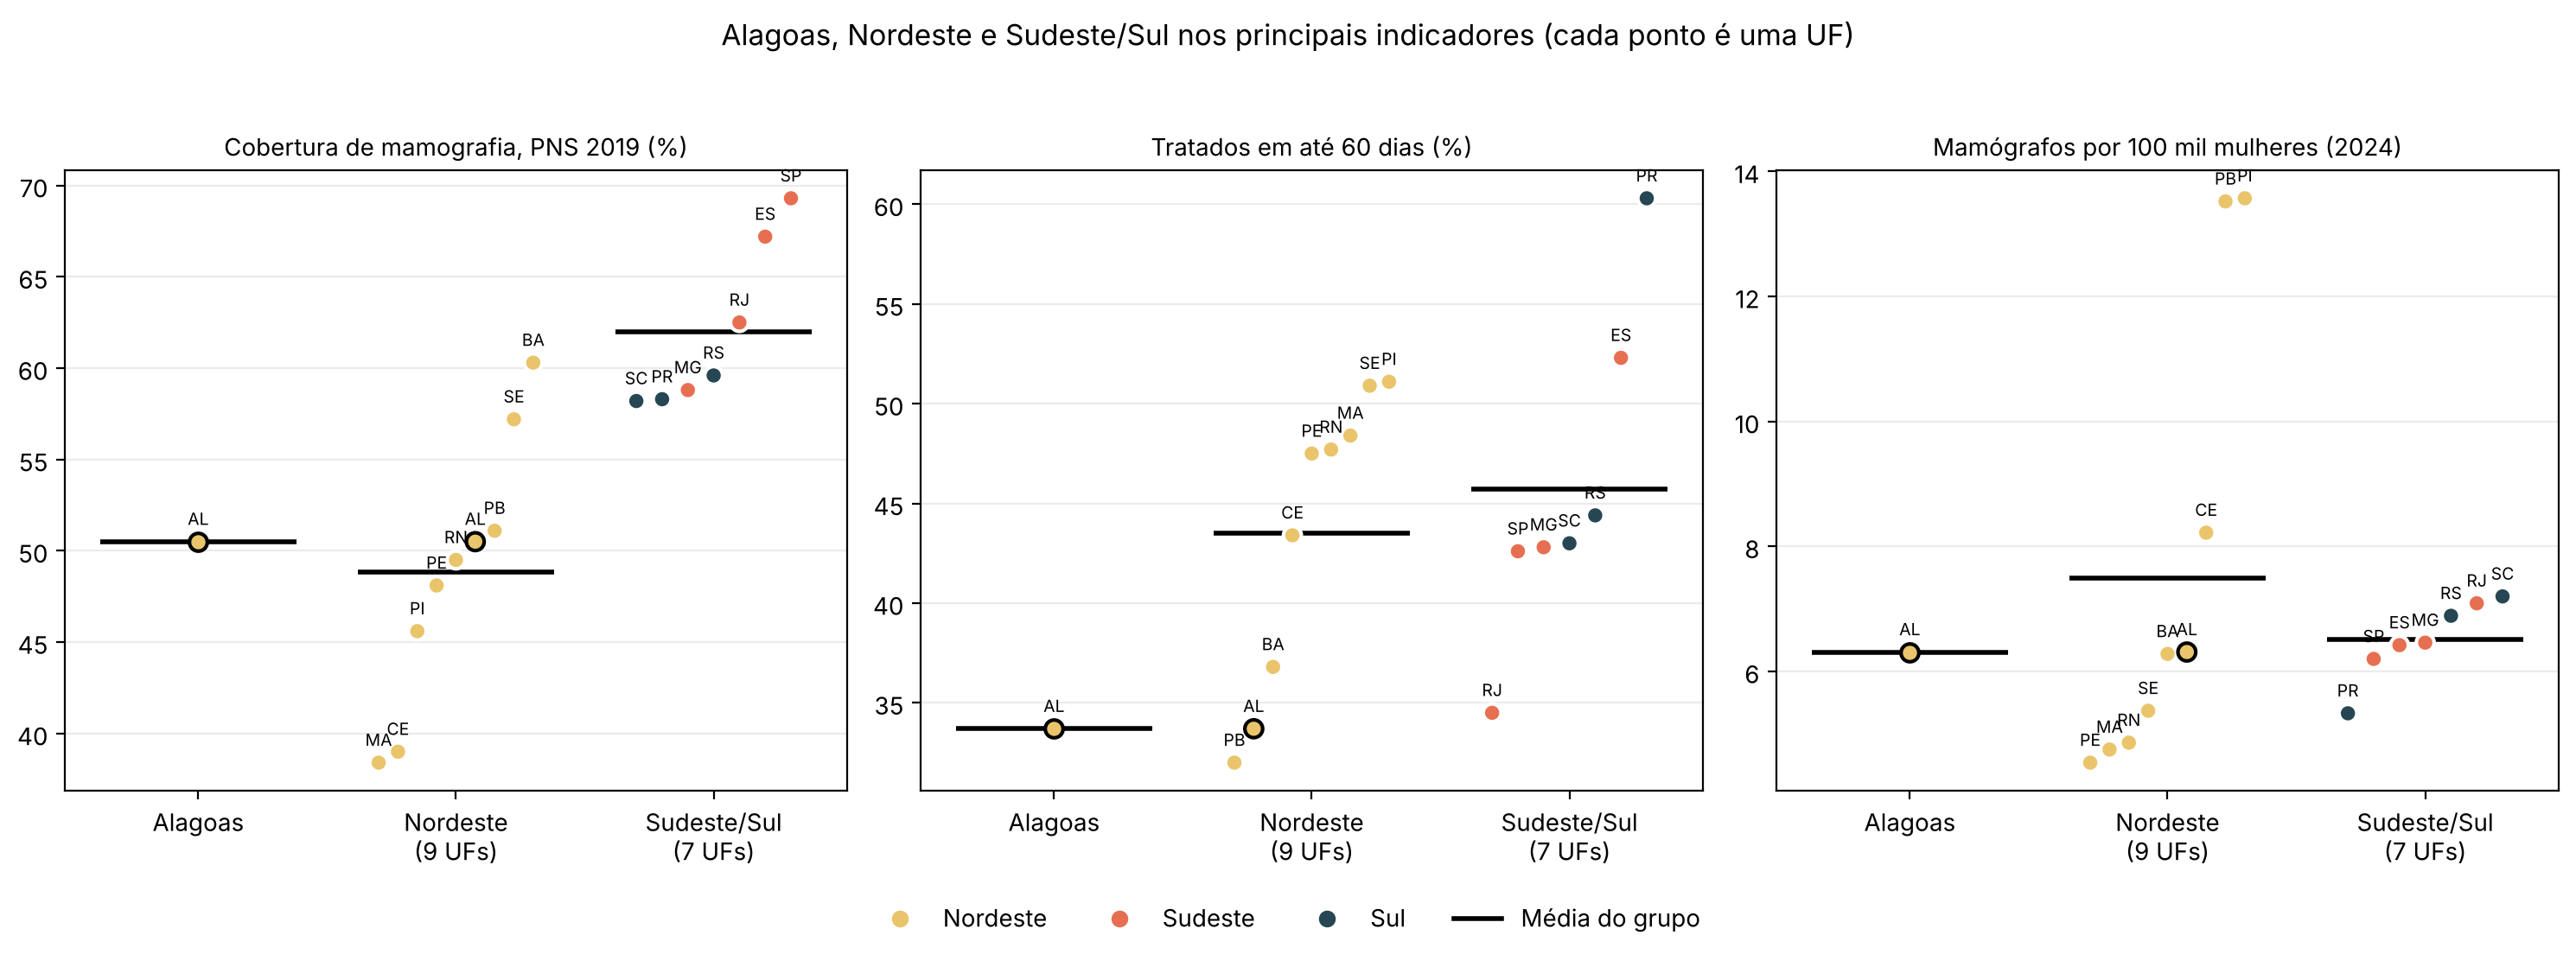

In [8]:
def painel(ax, col, titulo):
    grupos = [("Alagoas", df[df["uf_sigla"] == "AL"]),
              ("Nordeste\n(9 UFs)", ne),
              ("Sudeste/Sul\n(7 UFs)", ss)]
    for i, (nome, g) in enumerate(grupos):
        g = g.sort_values(col)
        xs = i + (np.linspace(-0.3, 0.3, len(g)) if len(g) > 1 else np.array([0.0]))
        ax.scatter(xs, g[col], c=g["regiao"].map(cores).tolist(), s=55, zorder=3,
                   edgecolors=["black" if u == "AL" else "white" for u in g["uf_sigla"]],
                   linewidths=1.5)
        for x, (_, r) in zip(xs, g.iterrows()):
            ax.annotate(r["uf_sigla"], (x, r[col]), xytext=(0, 7),
                        textcoords="offset points", ha="center", fontsize=7)
        ax.hlines(g[col].mean(), i - 0.38, i + 0.38, color="black", linewidth=2, zorder=2)
    ax.set_xticks(range(3))
    ax.set_xticklabels([n for n, _ in grupos])
    ax.set_title(titulo, fontsize=10)
    ax.grid(axis="y", alpha=0.25)

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
painel(axes[0], "cobertura_pns_2019", "Cobertura de mamografia, PNS 2019 (%)")
painel(axes[1], "pct_tratados_ate_60_dias", "Tratados em até 60 dias (%)")
painel(axes[2], "mamografos_por_100mil_mulheres", "Mamógrafos por 100 mil mulheres (2024)")

handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=cores[r], markersize=8, label=r)
           for r in ["Nordeste", "Sudeste", "Sul"]]
handles.append(plt.Line2D([0], [0], color="black", linewidth=2, label="Média do grupo"))
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False)
fig.suptitle("Alagoas, Nordeste e Sudeste/Sul nos principais indicadores (cada ponto é uma UF)")
plt.tight_layout(rect=(0, 0.06, 1, 0.95))
plt.show()

### B.2 Tabela comparativa

Além dos três indicadores do gráfico, a tabela traz incidência e mortalidade como contexto. A coluna de p-valor compara Nordeste × Sudeste/Sul com o teste de **Mann-Whitney**, que não exige distribuição normal. Como são 5 comparações, usamos a correção de Bonferroni (p < 0,05 ÷ 5 = 0,01) para dizer se a diferença resiste. Com 9 e 7 UFs, os p-valores são descritivos.

In [9]:
cols_B = ["cobertura_pns_2019", "pct_tratados_ate_60_dias", "mamografos_por_100mil_mulheres",
          "incid_taxa_ajustada", "mort_taxa_ajustada_2023"]
rot_B = {
    "cobertura_pns_2019": "Cobertura de mamografia, PNS 2019 (%)",
    "pct_tratados_ate_60_dias": "Tratados em até 60 dias (%)",
    "mamografos_por_100mil_mulheres": "Mamógrafos por 100 mil mulheres",
    "incid_taxa_ajustada": "Incidência ajustada",
    "mort_taxa_ajustada_2023": "Mortalidade ajustada 2023",
}

def linha_B(c):
    u = mannwhitneyu(ne[c], ss[c], alternative="two-sided")
    return {"Indicador": rot_B[c],
            "Alagoas": al[c],
            "Nordeste (média)": ne[c].mean(), "Nordeste (mediana)": ne[c].median(),
            "Sudeste/Sul (média)": ss[c].mean(), "Sudeste/Sul (mediana)": ss[c].median(),
            "Posição de AL (1 = maior)": int(df[c].rank(ascending=False)[df["uf_sigla"] == "AL"].iloc[0]),
            "p (NE × SE/S)": u.pvalue}

tab_B = pd.DataFrame([linha_B(c) for c in cols_B]).set_index("Indicador")
tab_B["Resiste à correção?"] = np.where(tab_B["p (NE × SE/S)"] < 0.05 / len(cols_B), "Sim", "Não")
tab_B["p (NE × SE/S)"] = tab_B["p (NE × SE/S)"].map(fmt_p)
tab_B.round(1)

,Alagoas,Nordeste (média),Nordeste (mediana),Sudeste/Sul (média),Sudeste/Sul (mediana),Posição de AL (1 = maior),p (NE × SE/S),Resiste à correção?
Indicador,,,,,,,,
"Cobertura de mamografia, PNS 2019 (%)",50.5,48.9,49.5,62.0,59.6,16,"0,002",Sim
Tratados em até 60 dias (%),33.7,43.5,47.5,45.7,43.0,24,"0,918",Não
Mamógrafos por 100 mil mulheres,6.3,7.5,6.3,6.5,6.5,14,"0,606",Não
Incidência ajustada,34.9,42.5,42.1,51.7,49.3,20,"0,470",Não
Mortalidade ajustada 2023,11.6,11.1,11.6,13.5,13.5,16,"0,031",Não


### B.3 Interpretação

**Cobertura.** O Sudeste/Sul tem cobertura bem maior que o Nordeste (média de 62,0% contra 48,9%, uma diferença de cerca de 13 pontos percentuais). É a única diferença da tabela que resiste à correção (p ≈ 0,002). Alagoas (50,5%) está em linha com o Nordeste.

**Oferta de mamógrafos.** Não há diferença entre os grupos: 7,5 por 100 mil mulheres no Nordeste e 6,5 no Sudeste/Sul (medianas de 6,3 e 6,5, p ≈ 0,61). A média do Nordeste é puxada por Paraíba e Piauí. Ou seja, a diferença de cobertura não vem acompanhada de mais equipamentos por mulher no Sudeste/Sul, e o gargalo parece estar em outro ponto, como uso, distribuição ou acesso. Alagoas (6,3) está na mediana do Nordeste.

**Tempo até o tratamento.** Nordeste (43,5%) e Sudeste/Sul (45,7%) não se distinguem (p ≈ 0,92), e o nível é baixo no país inteiro: nenhuma UF chega a 61% e a média das UFs é de 42%. Alagoas tem 33,7%, a 4ª menor entre as 27 UFs e a 2ª menor do Nordeste, atrás apenas da Paraíba.

**Contexto.** A incidência não difere de forma clara entre os grupos (p ≈ 0,47). A mortalidade é maior no Sudeste/Sul (13,5 contra 11,1, p ≈ 0,03), mas essa diferença não resiste à correção.

**Síntese para Alagoas.** O estado tem cobertura e oferta típicas do Nordeste, mas está entre os piores no início do tratamento em até 60 dias. Isso é **compatível** com um gargalo depois do diagnóstico, e não só no acesso ao exame. Não prova, porque os dados são agregados por UF e de períodos diferentes.

### B.4 Limitações

- **Médias simples das UFs.** Não são ponderadas pelo tamanho da população, e com 9 e 7 UFs uma UF atípica pesa bastante. Por isso a tabela traz também as medianas.
- **Alagoas está dentro do grupo Nordeste.** A comparação de Alagoas com o Nordeste inclui o próprio estado, o que reduz um pouco a diferença.
- **Tempo até o tratamento.** A base não informa o período nem a definição exata do indicador `pct_tratados_ate_60_dias`. Confirmar no dicionário de dados.
- **Períodos diferentes.** Cobertura PNS de 2019 e mamógrafos de 2024. Mamógrafos: indicador de oferta total (provavelmente público e privado), com mulheres de todas as idades no denominador.
- **Testes exploratórios.** Mann-Whitney com poucas UFs, sem controle de fatores como renda e urbanização.

## Parte C: cobertura do SUS × cobertura da PNS

Aqui calculamos quantas mamografias de rastreamento o SUS fez em cada UF para cada 100 mulheres da população feminina da base, e comparamos com a cobertura da PNS.

**Como a conta é feita:** `exames_sus_2024` ÷ `pop_feminina_estimada` × 100. O numerador conta os exames de rastreamento de mulheres de 50 a 69 anos feitos no SUS em 2024. O denominador é a população feminina estimada da base, de **todas as idades**.

**Por que não comparamos os valores direto:** a PNS mede o **% de mulheres** que fez mamografia nos últimos 2 anos, em qualquer serviço. O indicador do SUS conta **exames** em 1 ano, só no SUS, e por mulheres de todas as idades. As unidades são diferentes, então comparamos a **posição das UFs** (correlação de Spearman) e não os números.

### C.1 Exames do SUS por 100 mulheres

Brasil (27 UFs): 2.4 exames de rastreamento do SUS por 100 mulheres (todas as idades) em 2024


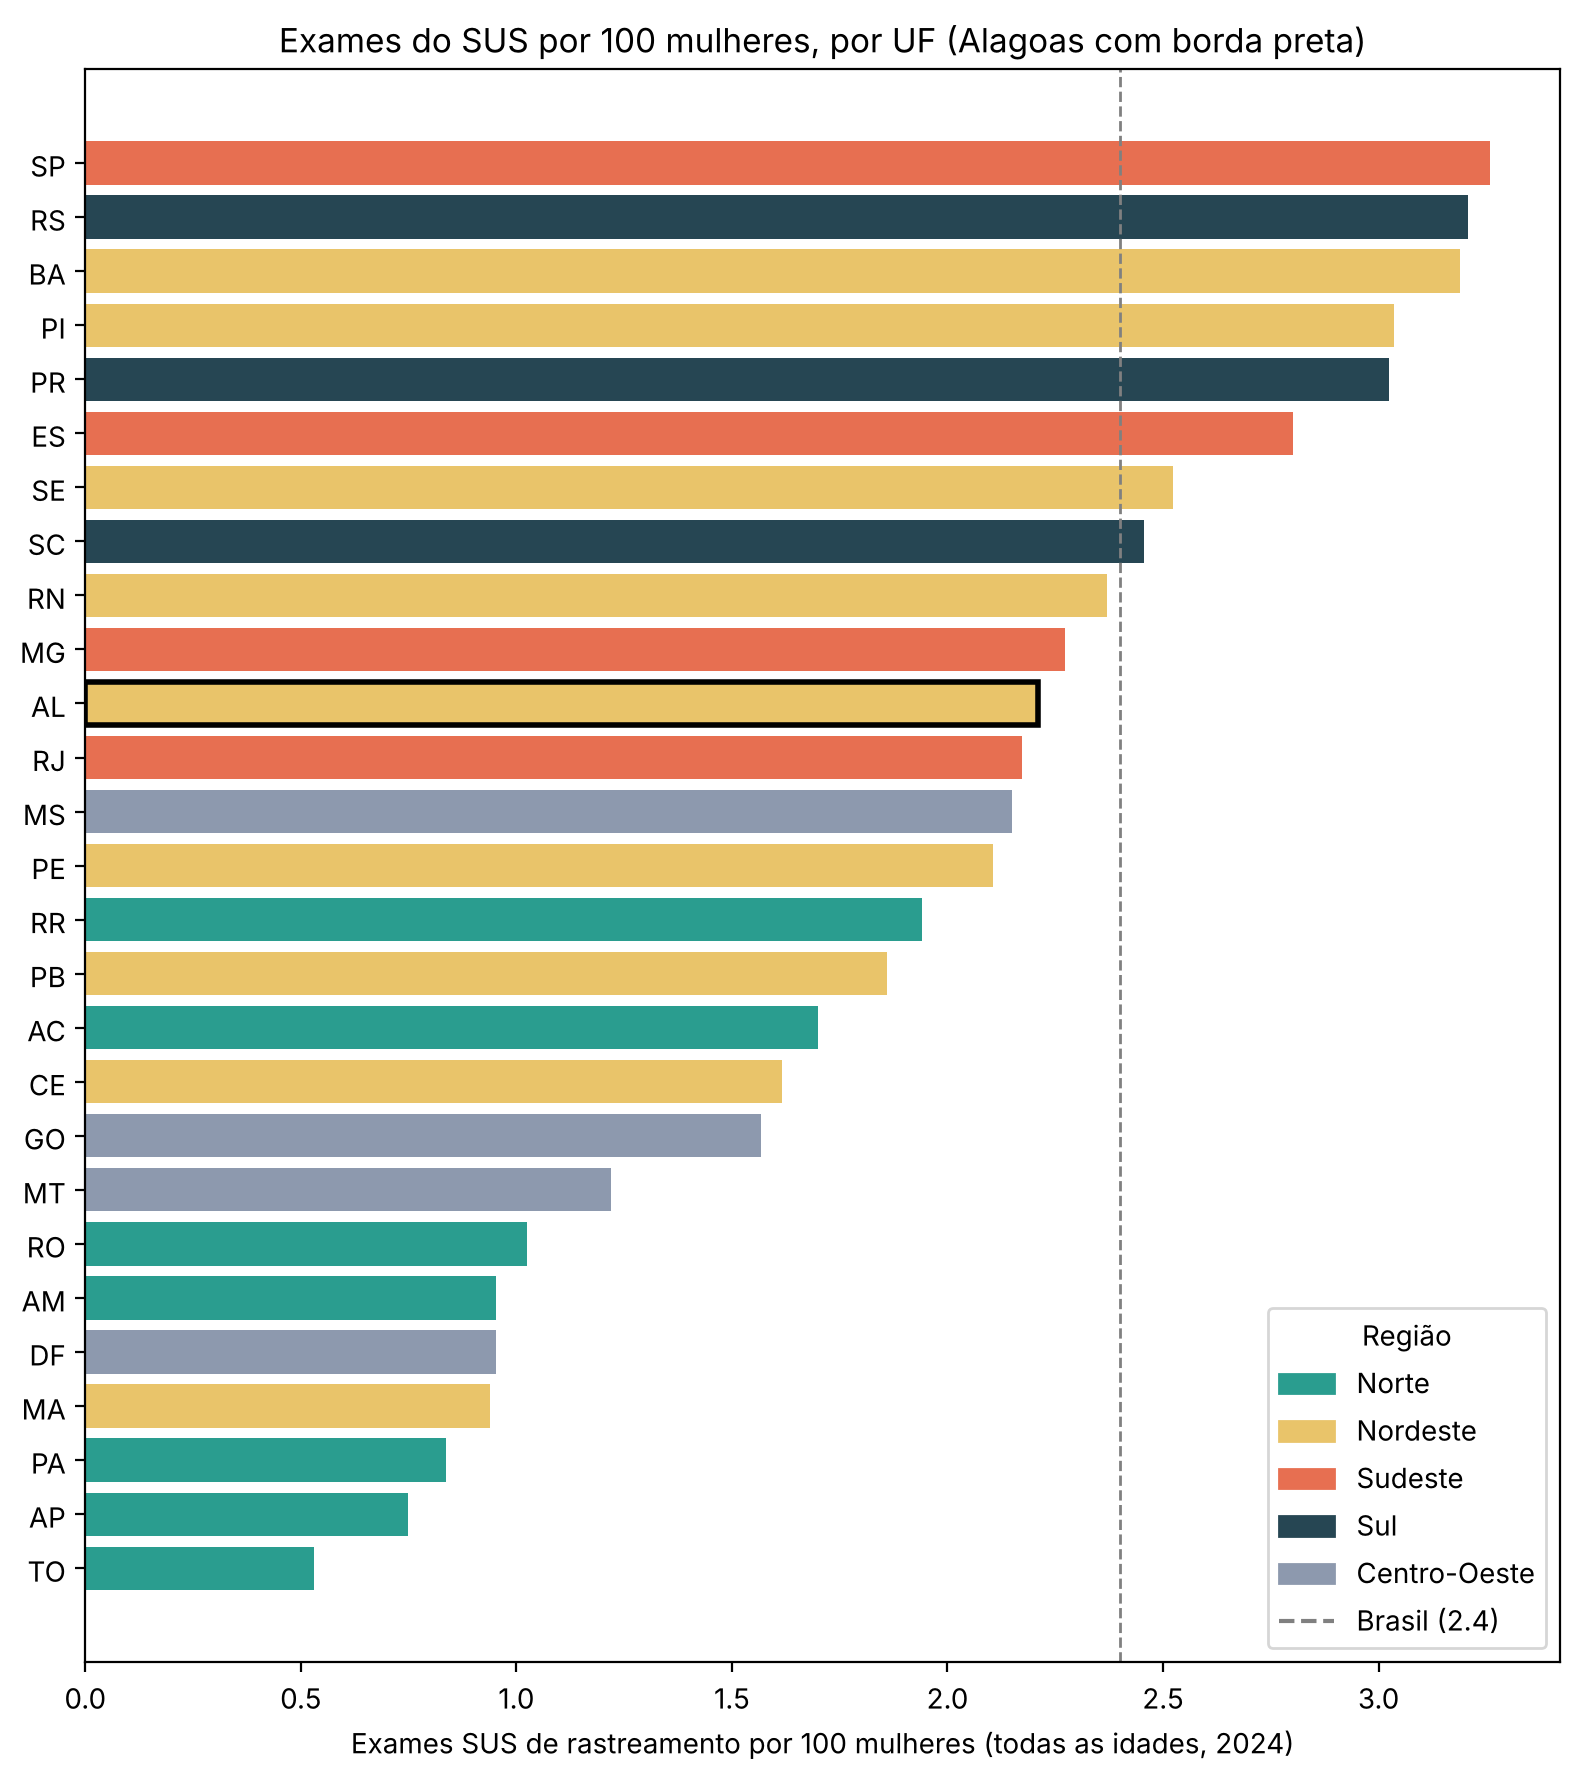

In [10]:
df["exames_por_100_mulheres"] = df["exames_sus_2024"] / df["pop_feminina_estimada"] * 100
brasil = df["exames_sus_2024"].sum() / df["pop_feminina_estimada"].sum() * 100
print(f"Brasil (27 UFs): {brasil:.1f} exames de rastreamento do SUS por 100 mulheres (todas as idades) em 2024")

r = df.sort_values("exames_por_100_mulheres", ascending=False)
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(r["uf_sigla"], r["exames_por_100_mulheres"],
        color=r["regiao"].map(cores).tolist(),
        edgecolor=["black" if u == "AL" else "none" for u in r["uf_sigla"]], linewidth=2)
ax.invert_yaxis()
ax.axvline(brasil, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Exames SUS de rastreamento por 100 mulheres (todas as idades, 2024)")
ax.set_title("Exames do SUS por 100 mulheres, por UF (Alagoas com borda preta)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in cores.values()]
ax.legend(handles + [plt.Line2D([0], [0], color="gray", linestyle="--")],
          list(cores.keys()) + [f"Brasil ({brasil:.1f})"], title="Região", loc="lower right")
plt.tight_layout()
plt.show()

### C.2 Comparação com a cobertura da PNS

SUS (2024) × PNS 2019: ρ = 0.61 (p = 0.001)
SUS (2024) × PNS 2013: ρ = 0.60 (p = 0.001)
SUS (2024) × PNS 2019, sem o DF: ρ = 0.71 (p = 0.000, n = 26)


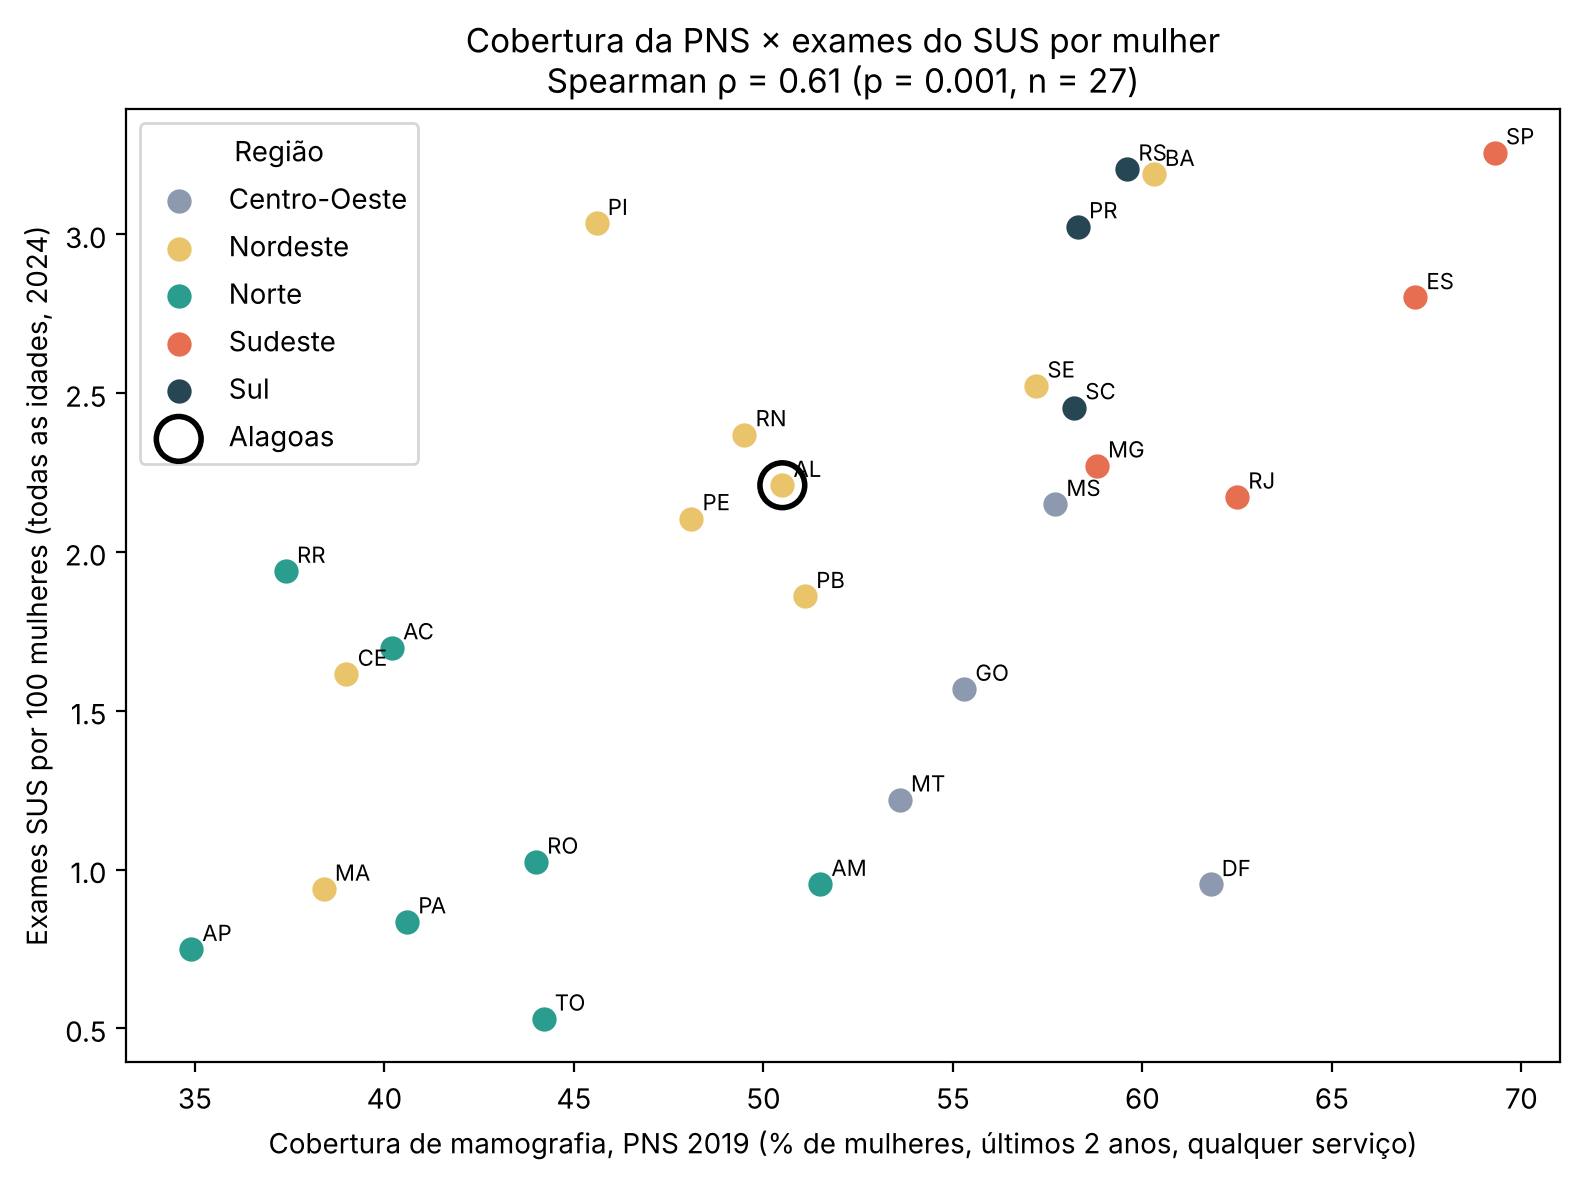

In [11]:
rho19, p19 = spearmanr(df["exames_por_100_mulheres"], df["cobertura_pns_2019"])
rho13, p13 = spearmanr(df["exames_por_100_mulheres"], df["cobertura_pns_2013"])
sem_df = df[df["uf_sigla"] != "DF"]
rho_sd, p_sd = spearmanr(sem_df["exames_por_100_mulheres"], sem_df["cobertura_pns_2019"])
print(f"SUS (2024) × PNS 2019: ρ = {rho19:.2f} (p = {p19:.3f})")
print(f"SUS (2024) × PNS 2013: ρ = {rho13:.2f} (p = {p13:.3f})")
print(f"SUS (2024) × PNS 2019, sem o DF: ρ = {rho_sd:.2f} (p = {p_sd:.3f}, n = {len(sem_df)})")

fig, ax = plt.subplots(figsize=(8, 6))
for regiao, g in df.groupby("regiao"):
    ax.scatter(g["cobertura_pns_2019"], g["exames_por_100_mulheres"],
               color=cores[regiao], label=regiao, s=60)
a = df[df["uf_sigla"] == "AL"]
ax.scatter(a["cobertura_pns_2019"], a["exames_por_100_mulheres"], s=260,
           facecolors="none", edgecolors="black", linewidths=2, label="Alagoas")
for _, rr in df.iterrows():
    ax.annotate(rr["uf_sigla"], (rr["cobertura_pns_2019"], rr["exames_por_100_mulheres"]),
                xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xlabel("Cobertura de mamografia, PNS 2019 (% de mulheres, últimos 2 anos, qualquer serviço)")
ax.set_ylabel("Exames SUS por 100 mulheres (todas as idades, 2024)")
ax.set_title(f"Cobertura da PNS × exames do SUS por mulher\nSpearman ρ = {rho19:.2f} (p = {p19:.3f}, n = {len(df)})")
ax.legend(title="Região")
plt.tight_layout()
plt.show()

### C.3 Onde as duas medidas discordam

A tabela compara a **posição** de cada UF nas duas medidas (1 = maior valor). Uma diferença negativa quer dizer que a UF está pior posicionada no SUS do que na PNS, e uma diferença positiva, o contrário. Aparecem as 6 UFs com maior diferença de cada lado.

In [12]:
df["pos_pns_2019"] = df["cobertura_pns_2019"].rank(ascending=False, method="min").astype(int)
df["pos_sus_2024"] = df["exames_por_100_mulheres"].rank(ascending=False, method="min").astype(int)
df["dif_posicao"] = df["pos_pns_2019"] - df["pos_sus_2024"]

gap = df[["uf_sigla", "regiao", "cobertura_pns_2019", "exames_por_100_mulheres",
          "pos_pns_2019", "pos_sus_2024", "dif_posicao"]].rename(columns={
    "uf_sigla": "UF", "regiao": "Região",
    "cobertura_pns_2019": "PNS 2019 (%)",
    "exames_por_100_mulheres": "Exames SUS por 100 mulheres",
    "pos_pns_2019": "Posição PNS", "pos_sus_2024": "Posição SUS", "dif_posicao": "Diferença"})
gap = gap.sort_values("Diferença")
pd.concat([gap.head(6), gap.tail(6)]).round(2).reset_index(drop=True)

,UF,Região,PNS 2019 (%),Exames SUS por 100 mulheres,Posição PNS,Posição SUS,Diferença
0,DF,Centro-Oeste,61.8,0.95,4,23,-19
1,RJ,Sudeste,62.5,2.17,3,12,-9
2,AM,Norte,51.5,0.95,14,22,-8
3,TO,Norte,44.2,0.53,20,27,-7
4,GO,Centro-Oeste,55.3,1.57,12,19,-7
5,MT,Centro-Oeste,53.6,1.22,13,20,-7
6,AL,Nordeste,50.5,2.21,16,11,5
7,AC,Norte,40.2,1.70,23,17,6
8,CE,Nordeste,39.0,1.62,24,18,6
9,RN,Nordeste,49.5,2.37,17,9,8


### C.4 Interpretação

**Nível.** No conjunto das 27 UFs, o SUS fez **2,4 exames de rastreamento por 100 mulheres** (de todas as idades) em 2024. Entre as UFs, o valor vai de 0,5 (Tocantins) a 3,3 (São Paulo). Alagoas tem 2,2, a 11ª maior taxa do país e igual à mediana do Nordeste (2,2). Esses valores são bem menores do que seriam com as mulheres de 50 a 69 anos no denominador, porque essa faixa é só uma parte da população feminina.

**Concordância com a PNS.** A posição das UFs nas duas medidas concorda de forma moderada a forte (ρ ≈ 0,61 com a PNS 2019, p ≈ 0,001, e ρ ≈ 0,60 com a PNS 2013, p ≈ 0,001). Sem o Distrito Federal, a correlação sobe para ρ ≈ 0,71. **Atenção:** parte dessa concordância pode vir da estrutura etária, e não da cobertura. UFs com população mais velha têm proporcionalmente mais mulheres de 50 a 69 anos, o que eleva a taxa por mulher de todas as idades, e a cobertura da PNS tende a acompanhar esse perfil. Por isso, o valor de ρ não deve ser lido como prova de que o SUS e a PNS medem a mesma coisa.

**Onde discordam.** O Distrito Federal é o caso mais claro: é o 4º na PNS (61,8%) e o 23º em exames do SUS por mulher (0,95). Rio de Janeiro (3º na PNS e 12º no SUS), Amazonas (14º e 22º), Tocantins (20º e 27º), Goiás (12º e 19º) e Mato Grosso (13º e 20º) também estão pior posicionados no SUS do que na PNS. No sentido oposto, Piauí (19º na PNS e 4º no SUS), Roraima (26º e 15º) e Rio Grande do Norte (17º e 9º) estão melhor posicionados no SUS. Uma explicação **compatível** é o uso de planos de saúde e serviços privados: a PNS capta exames feitos em qualquer serviço, enquanto o indicador do SUS só conta os exames públicos, e o denominador inclui mulheres com plano. Esta hipótese não foi testada aqui, porque falta o dado de cobertura de planos de saúde por UF.

**Alagoas.** O estado está na 11ª posição em exames do SUS e na 16ª na cobertura da PNS, melhor posicionado no SUS do que na PNS. Somado ao resultado da Parte B, o início do tratamento em até 60 dias (33,7%) é o ponto mais fraco de Alagoas, e não o volume de exames do SUS.

### C.5 Limitações

- **Denominador de todas as idades.** A população da base (`pop_feminina_estimada`) inclui mulheres de todas as idades, e não só as de 50 a 69 anos. A taxa não é, portanto, uma cobertura da população-alvo. UFs com população mais jovem (como as do Norte) têm menos mulheres de 50 a 69 anos e, por isso, taxas menores de forma mecânica. O ano dessa população deve ser confirmado no dicionário de dados.
- **Exames, não mulheres.** O SUS conta exames, e a mesma mulher pode fazer mais de um. A PNS conta mulheres. Por isso comparamos posições, e não valores.
- **Janelas de tempo diferentes.** Os exames são de 1 ano (2024), e a PNS pergunta sobre 2 anos e é de 2019, antes da pandemia.
- **Planos de saúde.** O denominador inclui mulheres com plano. Nas UFs com mais plano, a taxa do SUS subestima o atendimento das mulheres que dependem do SUS.
- **Subnotificação.** O Siscan tem problemas de registro que variam entre as UFs, e isso pode distorcer justamente a comparação entre regiões.
- **PNS.** Pesquisa por amostra, autorreferida, sem intervalo de confiança na base.
- **Refinamentos possíveis.** Usar como denominador só as mulheres de 50 a 69 anos, somar 2023 e 2024 para ter uma janela de 2 anos como a da PNS e, para o efeito dos planos, usar só as mulheres sem plano de saúde (dado da ANS por UF).

## Síntese das três partes

- **Parte A:** os dados são compatíveis com subdiagnóstico em parte do Norte/Nordeste, mas não separam "risco menor" de "menos diagnóstico".
- **Parte B:** a cobertura é bem maior no Sudeste/Sul (62,0% contra 48,9% no Nordeste), sem diferença na oferta de mamógrafos por mulher nem no tempo até o tratamento. Alagoas tem cobertura e oferta típicas, mas está entre as piores UFs no início do tratamento em até 60 dias (33,7%).
- **Parte C:** o SUS fez 2,4 exames de rastreamento por 100 mulheres (todas as idades) em 2024. A posição das UFs concorda com a da PNS (ρ ≈ 0,61), em parte por causa da estrutura etária, e o DF é a principal exceção.
- **Em conjunto:** o gargalo de Alagoas parece estar mais depois do diagnóstico do que no acesso ao exame. É uma leitura compatível com os dados, e não uma conclusão causal.